# functions for inspecting results

In [6]:
#function for loading saved results
import pickle
from pathlib import Path
from typing import Dict, Any, Tuple
def load_dicts_pickle(path: str | Path) -> Tuple[Dict[str, Any], Dict[str, Any], Dict[str, Any], Dict[str, Any], Dict[str, Any]]:
    """Load 5 dictionaries from a pickle file (in the same order they were saved)."""
    path = Path(path)
    with path.open("rb") as f:
        d1, d2, d3, d4, d5 = pickle.load(f)

    # Optional sanity checks
    for i, d in enumerate((d1, d2, d3, d4, d5), start=1):
        if not isinstance(d, dict):
            raise TypeError(f"Object #{i} in {path} is not a dict (got {type(d)!r}).")

    return d1, d2, d3, d4, d5


In [33]:
from rqpnn.rqpnn_parameterization import generate_ham_properties_from_params
from qip_task.qiptask_costfunc import compute_physical_rates
import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt

#set figure
base_fontsize = 10       # match paper
width_pt = 500

plt.rcParams.update({
    "font.size": base_fontsize,
    "axes.labelsize": base_fontsize,
    "axes.titlesize": base_fontsize,
    "xtick.labelsize": base_fontsize-1,
    "ytick.labelsize": base_fontsize-1,
    "legend.fontsize": base_fontsize-1,
    "text.usetex": True,       # stay with Matplotlib’s built‑in mathtext
    "font.family": "serif",       # use the document’s default serif
    "xtick.direction": "in",
    "ytick.direction": "in",
    "grid.alpha": 0.8,
    "grid.linestyle": ":",
})

def set_size(width_pt, fraction=1, aspect_ratio=0.62):
    inches_per_pt = 1.0 / 72.27
    fig_width = width_pt * inches_per_pt * fraction
    fig_height = fig_width * aspect_ratio
    return (fig_width, fig_height)

###Rates
#helper plotter
def pwc_plot_list_subplots(spec,times, values_list, rate_type="delta_cav",physical=True, trans="TOF"):
    """
    Plots a piecewise constant function for each array in values_list in its own subplot.
    
    Parameters:
        times (array-like): 1D array of time points.
        values_list (list of array-like): List where each element is an array of values
            corresponding to each time interval.
        rate_label (str): Label for the y-axis.
    """
    # Prepare time values to plot piecewise constant curves:
    # For times: [t0, t1, t2, ...] -> [t0, t1, t1, t2, t2, ...]
    times_plot = np.repeat(times, 2)[1:-1]  # (2n)
    if values_list.ndim==1: #when plotting tau
        values_list=[values_list]
    n_plots = len(values_list)
    if n_plots>1:
        if trans=="TOF":
            fig, axs = plt.subplots(n_plots, 1, figsize=set_size(width_pt,aspect_ratio=0.7/4*n_plots),sharex=True)
        elif trans=="rep2em":
            fig, axs = plt.subplots(n_plots, 1, figsize=set_size(width_pt,aspect_ratio=0.5),sharex=True)
        else:
            fig, axs = plt.subplots(n_plots, 1, figsize=set_size(width_pt,aspect_ratio=0.7),sharex=True)
    else:
        fig, axs = plt.subplots(n_plots, 1, figsize=set_size(width_pt,aspect_ratio=0.35),sharex=True)       

    colors=['b','r','g','m','c','y','k','orange']
    labels=['cav 1', 'cav 2', 'cav 3', 'cav 4', 'cav 5', 'cav 6']
    import matplotlib.colors as mcolors
    # Ensure axs is always a list (even if n_plots==1)
    if n_plots == 1:
        axs = [axs]
        colors=["purple"]
        labels=['cav 1 and 2']
    ymin=min(jnp.concatenate(values_list))
    ymax=max(jnp.concatenate(values_list))
    for i, ax in enumerate(axs):
        # Repeat each value to create a step plot
        values = np.repeat(values_list[i], 2)
        # Plot the piecewise constant function
        ax.plot(times_plot, np.real(values),color=colors[i], label=labels[i], linewidth=1)
        #ax.fill_between(times_plot, 0, np.real(values),color=colors[i], alpha=0.2)
        if spec.has_emitters==True:
            if physical==True:
                axs[-1].set_xlabel(r'$tg$')
                if rate_type=="delta_cav":
                    ax.set_ylabel(rf"$\delta_{i+1}^{{c}}/g$")
                elif rate_type=="kappa":
                    ax.set_ylabel(rf"$\kappa_{i+1}/g$")
                elif rate_type=="delta_em":
                    ax.set_ylabel(rf"$\delta_{i+1}^{{e}}/g$")
            elif physical==False:
                axs[-1].set_xlabel(r'$t*g/\tau(t)$')
                if rate_type=="delta_cav":
                    ax.set_ylabel(r"$\tau(t)\delta^{(c)}(t)/g$")
                elif rate_type=="kappa":
                    ax.set_ylabel(r"$\tau(t)\kappa^{(c)}(t)/g$")
                elif rate_type=="delta_em":
                    ax.set_ylabel(r"$\tau(t)\delta^{(e)}(t)/g$")
                elif rate_type=="tau":
                    ax.set_ylabel(r"$\Delta\tau(t)*g$")
        elif spec.has_emitters==False:
            if physical==True:
                axs[-1].set_xlabel(r'$t\chi_3$')
                if rate_type=="delta_cav":
                    ax.set_ylabel(rf"$\delta_{i+1}^{{c}}/\chi_3$")
                elif rate_type=="kappa":
                    ax.set_ylabel(rf"$\kappa_{i+1}/\chi_3$")
                elif rate_type=="delta_em":
                    ax.set_ylabel(rf"$\delta_{i+1}^{{e}}/\chi_3$")
            elif physical==False:
                axs[-1].set_xlabel(r'$t*\chi_3/\tau(t)$')
                if rate_type=="delta_cav":
                    ax.set_ylabel(r"$\Delta\tau(t)\delta^{(c)}/\chi_3$")
                elif rate_type=="kappa":
                    ax.set_ylabel(r"$\Delta\tau(t)\kappa^{(c)}/\chi_3$")
                elif rate_type=="delta_em":
                    ax.set_ylabel(r"$\Delta\tau(t)\delta^{(e)}/\chi_3$")
                elif rate_type=="tau":
                    ax.set_ylabel(r"$\Delta\tau(t)*g$")
        #ax.legend(loc='lower right')
        ax.set_xlim(0, times_plot[-1])
        ax.tick_params(axis='y', labelrotation=0,direction='inout')
        ax.tick_params(axis='x', labelrotation=0,direction='inout')
        if rate_type=="kappa":
            ax.set_ylim(0,ymax*1.05)
        else:
            ax.set_ylim(ymin*1.05,ymax*1.05)
        ax.grid(True) 

    plt.tight_layout()
    plt.show()
    return fig, axs


## time evolution
import rqpnn.rqpnn_spec as rqpnn_spec        #for defining rqpnn-specs
import rqpnn.rqpnn_system as rqpnn_system    #for defining rqpnn
import qip_task.qiptask_optimizer as qiptask_optimizer  #for optimizing rqpnn for a given QIP task
import qip_task.qiptask_generate_params as qiptask_generate_params  #for generating trainable parameters
import qip_task.qiptask_evolve as qiptask_evolver 
import dynamiqs as dq
def plot_timevolve_logbasis_report_new(rqpnnSpec,amp_dict,dict_opti,final_params,task_type="CZ",title_spec="",taskname="CZ"):

    #instantiate RQPNN system
    rqpnnSystem=rqpnn_system.RQPNNSystem(rqpnnSpec)
    optimizerQIPtask=qiptask_optimizer.OptimizerQIPtask(rqpnnSpec,dict_opti,final_params,rqpnnSystem.basis_conserved_mat)
    N_steps=len(amp_dict["max_tau"])
    H_para=rqpnnSystem._build_H_func(N_steps, amp_dict)
    H_t=H_para(final_params)
    
    scale=100
    tsave_evolve=jnp.linspace(0,N_steps,N_steps*scale+1)
    #run simulations
    results=[]
    init_states_timeevo=optimizerQIPtask.initial_states
    final_states_timeevo=optimizerQIPtask.target_array    
    for psi_init in init_states_timeevo:
        #results.append(dq.sesolve(H_t, psi_init, optimizer_cphase.tsave, solver=solver))
        results.append(dq.sesolve(H_t, psi_init, tsave_evolve, method=optimizerQIPtask.solver))
    ###construct a time vector for the physical time
    rate_tuple=compute_physical_rates(rqpnnSpec,final_params,amp_dict)
    tau_array=rate_tuple[0]
    tphys=jnp.linspace(0,tau_array[0],scale+1)
    tau_acc=tau_array[0]
    for i in range(1,len(tau_array)):
        tau_new=tau_array[i]
        newadd=jnp.linspace(tau_acc,tau_acc+tau_new,scale+1)
        tphys=jnp.concatenate([tphys,newadd[1:]])
        tau_acc+=tau_new
    #plot results
    # Create a figure and axis
    color=['r','b','g','y','m','c','k','orange']
    #color_dash=['r--','b--','g--','y--','m--','c--','k--','orange--']
    color_dash=['ro','bo','go','yo','mo','co','k*','orange*']
    color_dots=['r:','b:','g:','y:','m:','c:','k:','orange:']
    color_dotdash=['r-.','b-.','g-.','y-.','m-.','c-.','k-.','orange-.']
    # Prepare a single figure with 2×2 subplots
    if task_type=="CZchi3"  or task_type=="CZTLE":
        fig, axs = plt.subplots(4, 1, figsize=set_size(width_pt,aspect_ratio=0.8), sharex=True)
        label_state = ['0,0', '0,1', '1,0', '1,1']
        subtitles = [r"(a) Initial state: $|\psi(0)\rangle=|0,0\rangle_L$", r"(b) Initial state: $|\psi(0)\rangle=|0,1\rangle_L$",
                        r"(c) Initial state: $|\psi(0)\rangle=|1,0\rangle_L$", r"(d) Initial state: $|\psi(0)\rangle=|1,1\rangle_L$"]
    elif task_type=="CZchi3qutrit":
        fig, axs = plt.subplots(6, 1, figsize=set_size(width_pt,aspect_ratio=1.2), sharex=True)
        label_state = ['0,0', '0,1', '1,0', '1,1','0,2','1,2']
        subtitles = [r"(a) Initial state: $|\psi(0)\rangle=|0,0\rangle_L$", r"(b) Initial state: $|\psi(0)\rangle=|0,1\rangle_L$",
                        r"(c) Initial state: $|\psi(0)\rangle=|1,0\rangle_L$", r"(d) Initial state: $|\psi(0)\rangle=|1,1\rangle_L$","e","f"]        
    elif task_type=="TOF":
        fig, axs = plt.subplots(4, 2, figsize=set_size(width_pt,aspect_ratio=0.5), sharex=True)
        label_state = ['0,0,0', '0,0,1', '0,1,0', '0,1,1', '1,0,0', '1,0,1', '1,1,0', '1,1,1']
        subtitles = [r"(a) Initial state: $|\psi(0)\rangle=|0,0,0\rangle_L$", r"(b) Initial state: $|\psi(0)\rangle=|0,0,1\rangle_L$",
                        r"(c) Initial state: $|\psi(0)\rangle=|0,1,0\rangle_L$", r"(d) Initial state: $|\psi(0)\rangle=|0,1,1\rangle_L$",
                        r"(e) Initial state: $|\psi(0)\rangle=|1,0,0\rangle_L$", r"(f) Initial state: $|\psi(0)\rangle=|1,0,1\rangle_L$",
                        r"(g) Initial state: $|\psi(0)\rangle=|1,1,0\rangle_L$", r"(h) Initial state: $|\psi(0)\rangle=|1,1,1\rangle_L$"]
    elif task_type=="rep11chi3":
        fig, axs = plt.subplots(6, 1, figsize=set_size(width_pt,aspect_ratio=0.7), sharex=True)
        subtitles = [fr"(a) Initial state: $|0\rangle_L\otimes|1\rangle_3$",
                        fr"(b) Initial state: $|1\rangle_L\otimes|1\rangle_3$",
                        fr"(c) Initial state: $|3,0\rangle_{{1,2}}\otimes|1\rangle_3$",
                        fr"(d) Initial state: $|1,2\rangle_{{1,2}}\otimes|1\rangle_3$",
                        fr"(e) Initial state: $|0,3\rangle_{{1,2}}\otimes|1\rangle_3$",
                        fr"(f) Initial state: $|2,1\rangle_{{1,2}}\otimes|1\rangle_3$"]
                

        init_labels=[fr"$|\left(\langle 0|_L\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|0\rangle_L\otimes|1\rangle_3\right)|^2$",
                        fr"$|\left(\langle 1|_L\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|1\rangle_L\otimes|1\rangle_3\right)|^2$",
                        fr"$|\left(\langle 3,0|_{{1,2}}\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|3,0\rangle_{{1,2}}\otimes|1\rangle_3\right)|^2$",
                        fr"$|\left(\langle 1,2|_{{1,2}}\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|1,2\rangle_{{1,2}}\otimes|1\rangle_3\right)|^2$",
                        fr"$|\left(\langle 0,3|_{{1,2}}\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|0,3\rangle_{{1,2}}\otimes|1\rangle_3\right)|^2$",
                        fr"$|\left(\langle 2,1|_{{1,2}}\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|2,1\rangle_{{1,2}}\otimes|1\rangle_3\right)|^2$"]
        target_labels=[fr"$|\left(\langle 0|_L\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|0\rangle_L\otimes|1\rangle_3\right)|^2$",
                         fr"$|\left(\langle 1|_L\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|1\rangle_L\otimes|1\rangle_3\right)|^2$",
                         fr"$|\left(\langle 0|_L\otimes\langle 0|_3\right)U_{{RQPN}}(t)\left(|3,0\rangle_{{1,2}}\otimes|1\rangle_3\right)|^2$",
                         fr"$|\left(\langle 1|_L\otimes\langle 0|_3\right)U_{{RQPN}}(t)\left(|1,2\rangle_{{1,2}}\otimes|1\rangle_3\right)|^2$",
                            fr"$|\left(\langle 0,3|_{{1,2}}\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|0,3\rangle_{{1,2}}\otimes|1\rangle_3\right)|^2$",
                            fr"$|\left(\langle 2,1|_{{1,2}}\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|2,1\rangle_{{1,2}}\otimes|1\rangle_3\right)|^2$"]
        init_labels=[fr"abs$\left(\left(\langle 0|_L\otimes\langle 1_3|\right)|\psi(t)\rangle\right)^2$",
                    fr"abs$\left(\left(\langle 1|_L\otimes\langle 1_3|\right)|\psi(t)\rangle\right)^2$",
                        fr"abs$\left(\left(\langle 3_1,0_2|\otimes\langle 1_3|\right)|\psi(t)\rangle\right)^2$",
                        fr"abs$\left(\left(\langle 1_1,2_2|\otimes\langle 1|_3\right)|\psi(t)\rangle\right)|^2$",
                        fr"abs$\left(\left(\langle 0_1,3_2|\otimes\langle 1_3|\right)|\psi(t)\rangle\right)^2$",
                        fr"abs$\left(\left(\langle 2_1,1_2|\otimes\langle 1|_3\right)|\psi(t)\rangle\right)|^2$"]
        target_labels=[fr"abs$\left(\left(\langle 0|_L\otimes\langle 1_3|\right)|\psi(t)\rangle\right)^2$",
                        fr"abs$\left(\left(\langle 1|_L\otimes\langle 1_3|\right)|\psi(t)\rangle\right)^2$",
                    fr"abs$\left(\left(\langle 0|_L\otimes\langle 0_3|\right)|\psi(t)\rangle\right)^2$",
                        fr"abs$\left(\left(\langle 1|_L\otimes\langle 0_3|\right)|\psi(t)\rangle\right)^2$",
                        fr"abs$\left(\left(\langle 0_1,3_2|\otimes\langle 1_3|\right)|\psi(t)\rangle\right)^2$",
                        fr"abs$\left(\left(\langle 2_1,1_2|\otimes\langle 1|_3\right)|\psi(t)\rangle\right)|^2$"]
        phase_labels=[fr"arg$\left(\left(\langle 0|_L\otimes\langle 1_3|\right)|\psi(t)\rangle\right)/\pi$",
                        fr"arg$\left(\left(\langle 1|_L\otimes\langle 1_3|\right)|\psi(t)\rangle\right)/\pi$",
                    fr"arg$\left(\left(\langle 0|_L\otimes\langle 0_3|\right)|\psi(t)\rangle\right)/\pi$",
                        fr"arg$\left(\left(\langle 1|_L\otimes\langle 0_3|\right)|\psi(t)\rangle\right)/\pi$",
                        fr"arg$\left(\left(\langle 0_1,3_2|\otimes\langle 1_3|\right)|\psi(t)\rangle\right)/\pi$",
                        fr"arg$\left(\left(\langle 2_1,1_2|\otimes\langle 1|_3\right)|\psi(t)\rangle\right)/\pi$"]
    elif task_type=="rep12chi3":
        fig, axs = plt.subplots(4, 1, figsize=set_size(width_pt,aspect_ratio=0.7), sharex=True)
        subtitles = [fr"(a) Initial state: $|0\rangle_L\otimes|1\rangle_3$",
                        fr"(b) Initial state: $|1\rangle_L\otimes|1\rangle_3$",
                        fr"(c) Initial state: $|3,0\rangle_{{1,2}}\otimes|1\rangle_3$",
                        fr"(d) Initial state: $|1,2\rangle_{{1,2}}\otimes|1\rangle_3$"]
                
        init_labels=[fr"$|\left(\langle 0|_L\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|0\rangle_L\otimes|1\rangle_3\right)|^2$",
                        fr"$|\left(\langle 1|_L\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|1\rangle_L\otimes|1\rangle_3\right)|^2$",
                        fr"$|\left(\langle 0,3|_{{1,2}}\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|0,3\rangle_{{1,2}}\otimes|1\rangle_3\right)|^2$",
                        fr"$|\left(\langle 2,1|_{{1,2}}\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|2,1\rangle_{{1,2}}\otimes|1\rangle_3\right)|^2$"]
        target_labels=[fr"$|\left(\langle 0|_L\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|0\rangle_L\otimes|1\rangle_3\right)|^2$",
                         fr"$|\left(\langle 1|_L\otimes\langle 1|_3\right)U_{{RQPN}}(t)\left(|1\rangle_L\otimes|1\rangle_3\right)|^2$",
                            fr"$|\left(\langle 0|_L\otimes\langle 0|_3\right)U_{{RQPN}}(t)\left(|0,3\rangle_{{1,2}}\otimes|1\rangle_3\right)|^2$",
                            fr"$|\left(\langle 1|_L\otimes\langle 0|_3\right)U_{{RQPN}}(t)\left(|2,1\rangle_{{1,2}}\otimes|1\rangle_3\right)|^2$"]
        init_labels=[fr"abs$\left(\left(\langle 0|_L\otimes\langle 1_3|\right)|\psi(t)\rangle\right)^2$",
                    fr"abs$\left(\left(\langle 1|_L\otimes\langle 1_3|\right)|\psi(t)\rangle\right)^2$",
                        fr"abs$\left(\left(\langle 0_1,3_2|\otimes\langle 1_3|\right)|\psi(t)\rangle\right)^2$",
                        fr"abs$\left(\left(\langle 2_1,1_2|\otimes\langle 1|_3\right)|\psi(t)\rangle\right)^2$"]
        target_labels=[fr"abs$\left(\left(\langle 0|_L\otimes\langle 1_3|\right)|\psi(t)\rangle\right)^2$",
                        fr"abs$\left(\left(\langle 1|_L\otimes\langle 1_3|\right)|\psi(t)\rangle\right)^2$",
                    fr"abs$\left(\left(\langle 0|_L\otimes\langle 0_3|\right)|\psi(t)\rangle\right)^2$",
                        fr"abs$\left(\left(\langle 1|_L\otimes\langle 0_3|\right)|\psi(t)\rangle\right)^2$"]
        phase_labels=[fr"arg$\left(\left(\langle 0|_L\otimes\langle 1_3|\right)|\psi(t)\rangle\right)/\pi$",
                        fr"arg$\left(\left(\langle 1|_L\otimes\langle 1_3|\right)|\psi(t)\rangle\right)/\pi$",
                    fr"arg$\left(\left(\langle 0|_L\otimes\langle 0_3|\right)|\psi(t)\rangle\right)/\pi$",
                        fr"arg$\left(\left(\langle 1|_L\otimes\langle 0_3|\right)|\psi(t)\rangle\right)/\pi$"]
    elif task_type=="rep2em":
        fig, axs = plt.subplots(6, 1, figsize=set_size(width_pt,aspect_ratio=0.7), sharex=True)
        subtitles = [fr"(a) Initial state: $U_{{\mathrm{{in}}}}(|0\rangle_L\otimes|e,e\rangle_{{1,2}})$",
                        fr"(b) Initial state: $U_{{\mathrm{{in}}}}(|1\rangle_L\otimes|e,e\rangle_{{1,2}})$",
                        fr"(c) Initial state: $U_{{\mathrm{{in}}}}(|3,0\rangle_{{1,2}}\otimes|e,e\rangle_{{1,2}})$",
                        fr"(d) Initial state: $U_{{\mathrm{{in}}}}(|1,2\rangle_{{1,2}}\otimes|e,e\rangle_{{1,2}})$",
                        fr"(e) Initial state: $U_{{\mathrm{{in}}}}(|0,3\rangle_{{1,2}}\otimes|e,e\rangle_{{1,2}})$",
                        fr"(f) Initial state: $U_{{\mathrm{{in}}}}(|2,1\rangle_{{1,2}}\otimes|e,e\rangle_{{1,2}})$"]
        init_labels=[fr"$|\left(\langle 0|_L\otimes\langle e,e|_{{1,2}}\right)U_{{RQPN}}(t)(|0\rangle_L\otimes|e,e\rangle_{{1,2}})|^2$",
                        fr"$|\left(\langle 1|_L\otimes\langle e,e|_{{1,2}}\right)U_{{RQPN}}(t)(|1\rangle_L\otimes|e,e\rangle_{{1,2}})|^2$",
                        fr"$|\left(\langle 3,0|_{{1,2}}\otimes\langle e,e|_{{1,2}}\right)U_{{RQPN}}(t)(|3,0\rangle_{{1,2}}\otimes|e,e\rangle_{{1,2}})|^2$",
                        fr"$|\left(\langle 1,2|_{{1,2}}\otimes\langle e,e|_{{1,2}}\right)U_{{RQPN}}(t)(|1,2\rangle_{{1,2}}\otimes|e,e\rangle_{{1,2}})|^2$",
                        fr"$|\left(\langle 0,3|_{{1,2}}\otimes\langle e,e|_{{1,2}}\right)U_{{RQPN}}(t)(|0,3\rangle_{{1,2}}\otimes|e,e\rangle_{{1,2}})|^2$",
                        fr"$|\left(\langle 2,1|_{{1,2}}\otimes\langle e,e|_{{1,2}}\right)U_{{RQPN}}(t)(|2,1\rangle_{{1,2}}\otimes|e,e\rangle_{{1,2}})|^2$"]
        target_labels=[fr"$|\left(\langle 0|_L\otimes\langle e,e|_{{1,2}}\right)U_{{RQPN}}(t)(|0\rangle_L\otimes|e,e\rangle_{{1,2}})|^2$",
                         fr"$|\left(\langle 1|_L\otimes\langle e,e|_{{1,2}}\right)U_{{RQPN}}(t)(|1\rangle_L\otimes|e,e\rangle_{{1,2}})|^2$",
                         fr"$|\left(\langle 0|_L\otimes\langle g,e|_{{1,2}}\right)U_{{RQPN}}(t)(|3,0\rangle_{{1,2}}\otimes|e,e\rangle_{{1,2}})|^2$",
                         fr"$|\left(\langle 1|_L\otimes\langle g,e|_{{1,2}}\right)U_{{RQPN}}(t)(|1,2\rangle_{{1,2}}\otimes|e,e\rangle_{{1,2}})|^2$",
                        fr"$|\left(\langle 0|_L\otimes\langle e,g|_{{1,2}}\right)U_{{RQPN}}(t)(|0,3\rangle_{{1,2}}\otimes|e,e\rangle_{{1,2}})|^2$",
                         fr"$|\left(\langle 1|_L\otimes\langle e,g|_{{1,2}}\right)U_{{RQPN}}(t)(|2,1\rangle_{{1,2}}\otimes|e,e\rangle_{{1,2}})|^2$"
]
        init_labels=[fr"abs$\left(\left(\langle 0|_L\otimes\langle e_1,e_2|\right)|\psi\rangle \right)^2$",
                    fr"abs$\left(\left(\langle 1|_L\otimes\langle e_1,e_2|\right)|\psi\rangle \right)^2$",
                    fr"abs$\left(\left(\langle 3_1,0_2|\otimes\langle e_1,e_2|\right)|\psi\rangle \right)^2$",
                    fr"abs$\left(\left(\langle 1_1,2_2|\otimes\langle e_1,e_2|\right)|\psi\rangle \right)^2$",
                    fr"abs$\left(\left(\langle 0_1,3_2|\otimes\langle e_1,e_2|\right)|\psi\rangle \right)^2$",
                    fr"abs$\left(\left(\langle 2_1,1_2|\otimes\langle e_1,e_2|\right)|\psi\rangle \right)^2$"]
        target_labels=[fr"abs$\left(\left(\langle 0|_L\otimes\langle e_1,e_2|\right)|\psi\rangle \right)^2$",
                    fr"abs$\left(\left(\langle 1|_L\otimes\langle e_1,e_2|\right)|\psi\rangle \right)^2$",
                    fr"abs$\left(\left(\langle 0|_L\otimes\langle g_1,e_2|\right)|\psi\rangle \right)^2$",
                    fr"abs$\left(\left(\langle 1|_L|\otimes\langle g_1,e_2|\right)|\psi\rangle \right)^2$",
                    fr"abs$\left(\left(\langle 0|_L\otimes\langle e_1,g_2|\right)|\psi\rangle \right)^2$",
                    fr"abs$\left(\left(\langle 1|_L\otimes\langle e_1,g_2|\right)|\psi\rangle \right)^2$"]
        phase_labels=[fr"arg$\left(\left(\langle 0|_L\otimes\langle e_1,e_2|\right)|\psi\rangle \right)/\pi$",
                    fr"arg$\left(\left(\langle 1|_L\otimes\langle e_1,e_2|\right)|\psi\rangle \right)/\pi$",
                    fr"arg$\left(\left(\langle 0|_L\otimes\langle g_1,e_2|\right)|\psi\rangle \right)/\pi$",
                    fr"arg$\left(\left(\langle 1|_L|\otimes\langle g_1,e_2|\right)|\psi\rangle \right)/\pi$",
                    fr"arg$\left(\left(\langle 0|_L\otimes\langle e_1,g_2|\right)|\psi\rangle \right)/\pi$",
                    fr"arg$\left(\left(\langle 1|_L\otimes\langle e_1,g_2|\right)|\psi\rangle \right)/\pi$"]

        #              fr"$|\psi(t)\rangle=U^{{\dagger}}_{{\mathrm{{out}}}}|1\rangle_L\otimes|e,g\rangle_{{1,2}}$ probability"]
    #make specific plot for each task type
    subtitles[0]= f"{title_spec}\n{subtitles[0]}"
    for i,result in enumerate(results):
        if task_type=="TOF":
            n=i%4
            if i>3:
                m=1
            else:
                m=0
            ax=axs[n,m]
        else:
            ax = axs[i]
        states=result.states
        final_state=final_states_timeevo[i]
        init_state=init_states_timeevo[i]
        alpha1 = init_state.dag() @ states
        alpha2 = final_state.dag() @ states
        if task_type=="CZchi3" or task_type=="CZTLE":
            ax.plot(tphys, (abs(alpha1)**2).flatten(), color[i], linewidth=1,label=fr"abs$\left(\langle {label_state[i]}|_L|\psi(t)\rangle\right)^2$")#,label=fr"$|\langle{label_state[i]}|_L|\psi(t)\rangle|^2$")
            if i==0:
                phase_ref=jnp.angle(alpha1).flatten()/jnp.pi
            else:
                ax.plot(tphys, wrap_to_pi(jnp.angle(alpha1).flatten()-phase_ref*jnp.pi)/jnp.pi, color_dash[i],markerfacecolor="None", linewidth=1,
                        markersize=2,           # make individual stars a bit smaller (optional)
markevery=60,label=fr"arg$\left(\langle {label_state[i]}|_L|\psi(t)\rangle\right)/\pi$")#,           label=fr"phase($\langle{label_state[i]}|_L|\psi(t)\rangle$)/$\pi$")
        elif task_type=="CZchi3qutrit":
            ax.plot(tphys, (abs(alpha1)**2).flatten(), color[i], linewidth=1,label=fr"abs$\left(\langle {label_state[i]}|_L|\psi(t)\rangle\right)^2$")#,label=fr"$|\langle{label_state[i]}|_L|\psi(t)\rangle|^2$")
            if i==0:
                phase_ref=jnp.angle(alpha1).flatten()/jnp.pi
            else:
                ax.plot(tphys, wrap_to_pi(jnp.angle(alpha1).flatten()-phase_ref*jnp.pi)/jnp.pi, color_dash[i],linewidth=1,markerfacecolor="None", 
                        markersize=2,           # make individual stars a bit smaller (optional)
markevery=60,label=fr"arg$\left(\langle {label_state[i]}|_L|\psi(t)\rangle\right)/\pi$")#,           label=fr"phase($\langle{label_state[i]}|_L|\psi(t)\rangle$)/$\pi$")
        elif task_type=="TOF":
            if i==6:
                ax.plot(tphys, (abs(alpha1)**2).flatten(), color[i], linewidth=1,label=fr"abs$\left(\langle{label_state[i]}|_L|\psi(t)\rangle\right)^2$")
                j_list=[0,1,2,3,4,5,7,6]
                j=j_list[i]
                ax.plot(tphys, (abs(alpha2)**2).flatten(), color[j],alpha=0.7, linewidth=1,label=fr"abs$\left(\langle{label_state[j]}|_L|\psi(t)\rangle\right)^2$")
            elif i==7:
                j_list=[0,1,2,3,4,5,7,6]
                j=j_list[i]
                ax.plot(tphys, (abs(alpha2)**2).flatten(), color[j], linewidth=0.7,label=fr"abs$\left(\langle{label_state[j]}|_L|\psi(t)\rangle\right)^2$")

                ax.plot(tphys, (abs(alpha1)**2).flatten(), color[i],alpha=1, linewidth=1,label=fr"abs$\left(\langle{label_state[i]}|_L|\psi(t)\rangle\right)^2$")
            else:
                ax.plot(tphys, (abs(alpha1)**2).flatten(), color[i], linewidth=1,label=fr"abs$\left(\langle{label_state[i]}|_L|\psi(t)\rangle\right)^2$")
        elif task_type=="rep11chi3" or task_type=="rep12chi3" or task_type=="rep2em":
            ax.plot(tphys, (abs(alpha1)**2).flatten(), color[i], linewidth=1,label=init_labels[i])
            if task_type=="rep2em" and i>1:
                ax.plot(tphys, (abs(alpha2)**2).flatten(), color_dots[i], linewidth=1,label=target_labels[i])
            if i>1 and i<4 and task_type!="rep2em":
                ax.plot(tphys, (abs(alpha2)**2).flatten(), color_dots[i], linewidth=1,label=target_labels[i])
            if i==0:
                phase_ref=jnp.angle(alpha2).flatten()/jnp.pi
            else:
                ax.plot(tphys,wrap_to_pi(jnp.angle(alpha2).flatten()-phase_ref*jnp.pi)/jnp.pi, color_dash[i],markersize=2,markevery=80,markerfacecolor="None", label=phase_labels[i])
                if i!=5:
                    phase=wrap_to_pi(jnp.angle(alpha2).flatten()-phase_ref*jnp.pi)/jnp.pi          
        #ax.set_ylabel('Coefficients', fontsize=14)
        ax.set_xlim(0, tphys[-1])  # Set x-axis limits to the total time
        if task_type=="TOF":
            ax.set_ylim(-0.05, 1.1)
            ax.set_xlim(-0.05, 2.05)
            ax.grid(True, alpha=1.0, linestyle=":")
            ax.legend(loc='upper center',markerscale=0.8, fontsize=8,ncol=1)#,bbox_to_anchor=(0.5, 0.8),frameon=True)#, facecolor='none', framealpha=0)
            axs[3,1].set_xlabel(r"$t \chi_3$") 
            axs[3,0].set_xlabel(r"$t \chi_3$") 
        else:
            ax.set_ylim(-1.1, 1.1)
            ax.grid(True, alpha=1.0, linestyle=":")
            ax.legend(loc='lower center', fontsize=8, borderaxespad=0.0)#,bbox_to_anchor=(0.5, 0.5))
            #ax.legend(loc='best',markerscale=0.8, fontsize=9,bbox_to_anchor=(1.02, 1.0),frameon=False)#, facecolor='none', framealpha=0)

            if rqpnnSpec.M_em == rqpnnSpec.M_cav:
                axs[-1].set_xlabel(r"$t g$")
            else:
                axs[-1].set_xlabel(r"$t \chi_3$")        
    # shared x-label on the last row

    # Make layout tight so labels/legends don’t overlap
    plt.show()
def wrap_to_pi(theta):
    """
    Map any real-valued phase (rad) to the interval (-π, π].

    Parameters
    ----------
    theta : array-like
        Phase(s) in radians.

    Returns
    -------
    wrapped : same shape as `theta`
        Phase mapped to (-π, π].
    """
    return (theta + jnp.pi) % (2 * jnp.pi) - jnp.pi

#coupling matrix
import jax
import matplotlib.colors as colors
##plot coupling matrix
def plot_couplingmatrix(spec,params_train_dict,params_amp_dict, title="Heatmap", xlabel="Column", ylabel="Row",
                        cmap="bwr", colorbar_label="Value",
                        fmt=".2f",opt_running=True):
    """
    Plots a heatmap of a JAX array with the numerical value of each element shown.
    The colorbar is centered with white corresponding to 0.
    
    Parameters:
    matrix: A jax.numpy array to visualize.
    title (str): Title of the heatmap.
    xlabel (str): Label for the x-axis.
    ylabel (str): Label for the y-axis.
    cmap (str): Colormap to use (default "bwr" for blue-white-red).
    colorbar_label (str): Label for the colorbar.
    figsize (tuple): Figure size in inches.
    fmt (str): String format for annotating each cell.
    """
    params_ham_dict=generate_ham_properties_from_params(spec,params_train_dict,params_amp_dict)
    coeff_mat=params_ham_dict["coeff_mat"]
    # Convert the JAX array to a NumPy array.
    matrix_np = jax.device_get(coeff_mat.real)
    
    # Create a normalization that centers at 0.
    fig, ax=plot_matrix(matrix_np,"Coefficient matrix","coefficient matrix plot",aspect_ratio=0.5)

import numpy as np
import matplotlib.colors as colors

def plot_matrix(
    matrix_np,
    title,
    logname,
    xlabel="Column",
    ylabel="Row",
    cmap="bwr",
    colorbar_label="Value",
    fmt=".2f",
    aspect_ratio=0.7,
    tick_start=1,
    dark_bg_luma_threshold=0.35,
):
    matrix_np = np.asarray(matrix_np)
    nrows, ncols = matrix_np.shape

    amp = np.nanmax(np.abs(matrix_np))
    amp = max(float(amp), 0.01)
    norm = colors.TwoSlopeNorm(vmin=-amp, vcenter=0.0, vmax=amp)

    fig, ax = plt.subplots(
        figsize=set_size(232.0 , aspect_ratio=aspect_ratio),
        constrained_layout=True
    )

    im = ax.imshow(
        matrix_np,
        cmap=cmap,
        norm=norm,
        aspect="auto",
        interpolation="nearest"
    )

    ax.set_title(xlabel)
    #ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    # ticks labeled from 1
    ax.set_xticks(np.arange(ncols))
    ax.set_yticks(np.arange(nrows))
    ax.set_xticklabels(np.arange(tick_start, tick_start + ncols))
    ax.set_yticklabels(np.arange(tick_start, tick_start + nrows))
    ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)

    # gridlines between cells
    ax.set_xticks(np.arange(-0.5, ncols, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, nrows, 1), minor=True)
    ax.grid(which="minor", linestyle=":", linewidth=0.5)
    ax.tick_params(which="minor", bottom=False, left=False)

    # annotations: black text; add white *outline* only on dark background
    for i in range(nrows):
        for j in range(ncols):
            val = matrix_np[i, j]
            if np.isnan(val):
                continue
            val = float(val)

            r, g, b, _ = im.cmap(im.norm(val))
            luma = 0.2126 * r + 0.7152 * g + 0.0722 * b

            t = ax.text(
                j, i, f"{val:{fmt}}",
                ha="center", va="center",
                color="black",
                fontsize=plt.rcParams["font.size"] - 1,
            )



    cbar = fig.colorbar(im, ax=ax, shrink=0.9, pad=0.02)
    cbar.set_label(colorbar_label,rotation=270)
    plt.show()
    return fig, ax



# inspect results

STEP 2 OF ONE-WAY REPEATER WITH CHI3
DURATION: 3.808/χ₃
CAVITY DETUNINGS


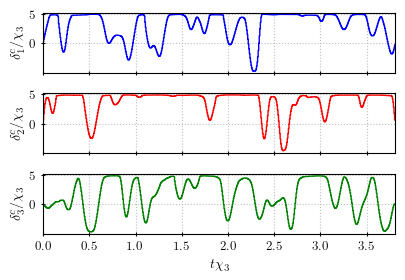

CAVITY COUPLINGS


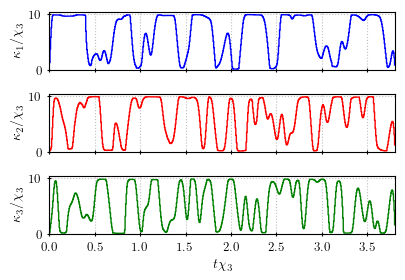

COUPLING MATRIX


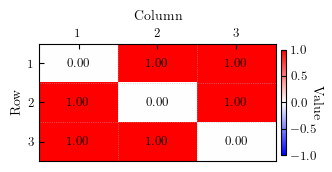

TIME EVOLUTION OF EACH INPUT STATE
excitation_numbers was list
excitation_numbers was list
excitation_numbers was list
excitation_numbers was list
excitation_numbers was list
excitation_numbers was list
excitation_numbers was list
excitation_numbers was list
mask {'tau': False, 'kappa': True, 'delta_em': True, 'S_in_Rmat': False, 'coeff_vec': False, 'delta_cav': True}
No emitters in system -> do not  include delta_em
N_pieces 640
building hamiltonian


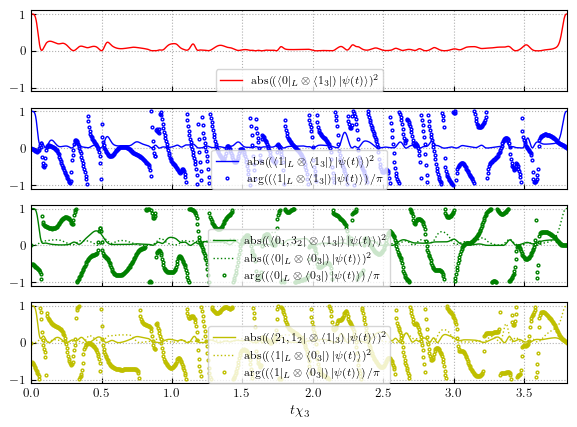

In [48]:
#choose one of the following results
transform="TOF"         #three-qubit Toffoli gate
transform="rep2em"      #one-way repeater using two-level emitters
transform="rep11chi3"   #first step of one-way repeater using chi3-nonlinearities
transform="rep12chi3"   #second step of one-way repeater using chi3-nonlinearities
#transform="CZchi3"      #CZ gate using chi3-nonlinearities
#transform="CZTLE"       #CZ gate using two-level emitters
#transform="CZchi3qutrit"#qubit-qutrit CZ gate using chi3-nonlinearities
if transform=="TOF":
    print("THREE-QUBIT TOFFOLI GATE")
    final_params, amp_dict,cfg_para,dict_system, dict_opti=load_dicts_pickle("Toffoli_res.pkl")
elif transform=="rep2em":
    print("ONE-WAY REPEATER WITH TLES")
    final_params, amp_dict,cfg_para,dict_system, dict_opti=load_dicts_pickle("repeaterTLEs_res.pkl")
elif transform=="rep11chi3":
    print("STEP 1 OF ONE-WAY REPEATER WITH CHI3")
    final_params, amp_dict,cfg_para,dict_system, dict_opti=load_dicts_pickle("repeaterChi3_step1_res.pkl")
elif transform=="rep12chi3":
    print("STEP 2 OF ONE-WAY REPEATER WITH CHI3")
    final_params, amp_dict,cfg_para,dict_system, dict_opti=load_dicts_pickle("repeaterChi3_step2_res.pkl")
elif transform=="CZchi3":
    print("CZ GATE WITH CHI3 (QUBIT-QUBIT)")
    final_params, amp_dict,cfg_para,dict_system, dict_opti=load_dicts_pickle("CZ_Chi3_res.pkl")
elif transform=="CZchi3qutrit":
    print("CZ GATE WITH CHI3 (QUBIT-QUTRIT)")
    final_params, amp_dict,cfg_para,dict_system, dict_opti=load_dicts_pickle("CZqutrit_Chi3_res.pkl")
elif transform=="CZTLE":
    print("CZ GATE WITH TLEs (QUBIT-QUBIT)")
    final_params, amp_dict,cfg_para,dict_system, dict_opti=load_dicts_pickle("CZ_TLE_res.pkl")

rqpnnSpec=rqpnn_spec.RQPNNSpec(dict_system["M_cav"],dict_system["M_em"],tuple(dict_system["N_exc_list"]))
#generate hamiltonian properties
params_ham_dict=generate_ham_properties_from_params(rqpnnSpec,final_params,amp_dict)
#calcaulte physical rates
rate_tuple=compute_physical_rates(rqpnnSpec,final_params,amp_dict)

tau_rates=rate_tuple[0]
delta_cav_physical=rate_tuple[1]
kappa_physical=rate_tuple[2]
tphys=jnp.zeros(shape=(len(tau_rates)+1))
for i in range(len(tau_rates)):
    tphys=tphys.at[i+1].set(tphys[i]+tau_rates[i])
values_list=[kappa_physical[5],delta_cav_physical[5]]
times_plot = np.repeat(tphys, 2)[1:-1]  # (2n)
n_plots = len(values_list)

width_pt = 300        # set width of the plots
T=tphys[-1]
if transform=="CZTLE" or transform=="rep2em":
    print("DURATION:", fr"{T:.3f}/g")
else:
    print("DURATION:", fr"{T:.3f}/χ₃")
print("CAVITY DETUNINGS")
pwc_plot_list_subplots(rqpnnSpec,tphys, delta_cav_physical, rate_type="delta_cav",physical=True, trans=transform)
print("CAVITY COUPLINGS")
pwc_plot_list_subplots(rqpnnSpec,tphys, kappa_physical, rate_type="kappa",physical=True, trans=transform)

if transform=="rep2em" or transform=="CZTLE":
    print("TLE DETUNINGS")
    pwc_plot_list_subplots(rqpnnSpec,tphys, rate_tuple[3], rate_type="delta_em",physical=True, trans=transform)

print("COUPLING MATRIX")
plot_couplingmatrix(rqpnnSpec,final_params,amp_dict)



width_pt = 500
print("TIME EVOLUTION OF EACH INPUT STATE")
plot_timevolve_logbasis_report_new(rqpnnSpec,amp_dict,dict_opti,final_params,task_type=transform,title_spec="")


In [ ]:
#load results
final_params, amp_dict,cfg_para,dict_system, dict_opti=load_dicts_pickle("CZ_Chi3_res.pkl")
#print results
print(final_params)
print(amp_dict)
print(cfg_para)
print(dict_system)
print(dict_opti)

{'S_in_Rmat': Array([0., 0., 0., 0., 0., 0.], dtype=float32), 'coeff_vec': Array([ 5.1639066e-04,  2.8558029e-04, -3.6394763e+00,  3.4526124e+00,
        8.1386953e-04, -3.8153648e-05], dtype=float32), 'delta_cav': Array([[-23.08523   , -30.7569    , -32.842506  , -33.69908   ,
        -32.78639   , -25.857222  , -12.745242  ,  -6.127509  ,
          0.82329774,   0.49912167,   0.15961808,  -0.16754067,
         -4.278532  ,  -6.178576  ,  -7.556051  ,  -7.0258236 ,
         -5.9672008 ,  -5.8081846 ,  -5.816332  ,  -6.0624013 ,
         -6.4387317 ,  -6.5747085 ,  -7.06597   ,  -9.113507  ,
         -8.9419    ,  -8.684875  ,  -9.447525  ,  -7.2958665 ,
         -6.8396397 ,  -6.5094924 ,  -6.0181    ,  -5.5733366 ,
         -5.1346836 ,  -5.187819  ,  -7.3828945 ,  -6.27056   ,
         -9.088343  ,  -2.8346484 ,  -0.10697819,   0.26393995,
          0.63938403,   1.3136312 ,  -7.7323203 , -13.508781  ,
        -25.837748  , -32.040737  , -32.262882  , -31.160675  ,
        -28.76517